   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

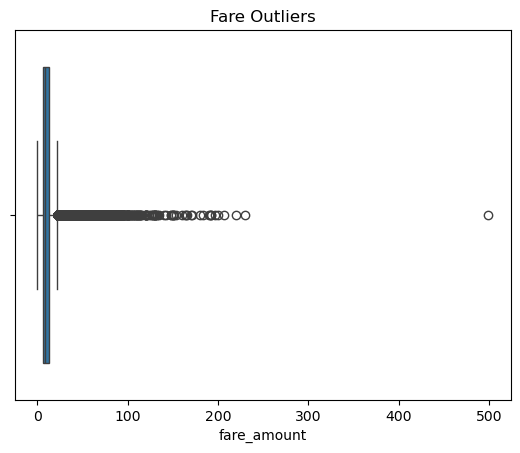

Dataset shape after preprocessing: (178573, 11)


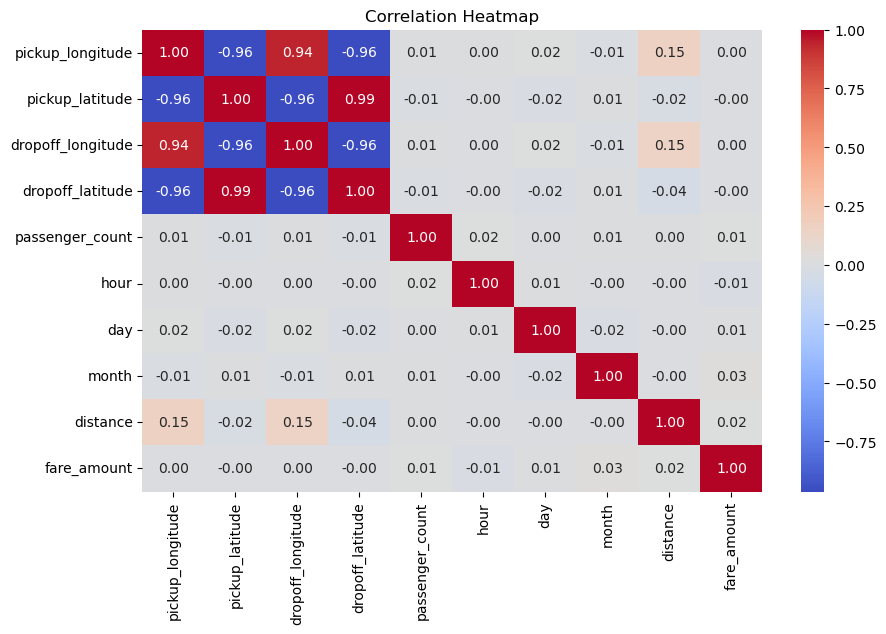


Model Comparison:
               Model  R2 Score      RMSE       MAE
0  Linear Regression  0.001667  4.162875  3.316219
1      Random Forest  0.731786  2.157726  1.518223

Model with higher R2 and lower RMSE/MAE performs better.


In [3]:
# Uber Fare Prediction using Linear Regression and Random Forest

# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# 2. Load dataset
df = pd.read_csv(r"C:\Users\Ritesh Bhosale\Downloads\BE prac\ML\Prac 1\uber.csv")
print(df.head())
print(df.isnull().sum())

# 3. Preprocess dataset
df.drop(columns=['Unnamed: 0', 'key'], errors='ignore', inplace=True)
df.dropna(inplace=True)

df['pickup_datetime'] = pd.to_datetime(
    df['pickup_datetime'], errors='coerce', utc=True
)
df.dropna(subset=['pickup_datetime'], inplace=True)

df = df[
    (df['fare_amount'] > 0) &
    (df['passenger_count'].between(1, 6)) &
    (df['pickup_longitude'].between(-180, 180)) &
    (df['dropoff_longitude'].between(-180, 180)) &
    (df['pickup_latitude'].between(-90, 90)) &
    (df['dropoff_latitude'].between(-90, 90)) &
    (df['pickup_longitude'] != 0) &
    (df['dropoff_longitude'] != 0) &
    (df['pickup_latitude'] != 0) &
    (df['dropoff_latitude'] != 0)
].copy()

df['hour'] = df['pickup_datetime'].dt.hour
df['day'] = df['pickup_datetime'].dt.day
df['month'] = df['pickup_datetime'].dt.month

# Calculate trip distance
lat1 = np.radians(df['pickup_latitude'])
lat2 = np.radians(df['dropoff_latitude'])
lon1 = np.radians(df['pickup_longitude'])
lon2 = np.radians(df['dropoff_longitude'])

a = (np.sin((lat2-lat1)/2)**2 +
     np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2)

df['distance'] = 6371 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

# 4. Identify and remove fare outliers using IQR
sns.boxplot(x=df['fare_amount'])
plt.title("Fare Outliers")
plt.show()

Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)
IQR = Q3 - Q1

df = df[
    df['fare_amount'].between(Q1 - 1.5*IQR, Q3 + 1.5*IQR)
].copy()

print("Dataset shape after preprocessing:", df.shape)

# 5. Check correlation
features = [
    'pickup_longitude', 'pickup_latitude',
    'dropoff_longitude', 'dropoff_latitude',
    'passenger_count', 'hour', 'day', 'month', 'distance'
]

plt.figure(figsize=(10, 6))
sns.heatmap(df[features + ['fare_amount']].corr(),
            annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

# 6. Split data
X = df[features]
y = df['fare_amount']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 7. Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)

# 8. Random Forest Regression
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

# 9. Evaluate and compare models
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'R2 Score': [
        r2_score(y_test, pred_lr),
        r2_score(y_test, pred_rf)
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(y_test, pred_lr)),
        np.sqrt(mean_squared_error(y_test, pred_rf))
    ],
    'MAE': [
        mean_absolute_error(y_test, pred_lr),
        mean_absolute_error(y_test, pred_rf)
    ]
})

print("\nModel Comparison:")
print(results)

# 10. Conclusion
print("\nModel with higher R2 and lower RMSE/MAE performs better.")